# 第 5 章 DataFrame 与 Spark SQL —— 代码实操

> 配套笔记：`../notes/08_第5章_DataFrame与SparkSQL.md`
> 数据：`../data/sales_data.csv`（销售信息表，5 行样例）、`../data/article.txt`（词频用）
> 课件里的 `sqlContext` 是 Spark 1.x/2.x 的老写法，这里用 `sqlContext = spark` 起别名，
> 所以课件代码可以原样粘贴运行；新写法 `spark.sql(...)` 同时给出，两种都能跑。

In [1]:
import os
os.environ.setdefault("JAVA_HOME", r"D:\jdk-21")

from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("ch5-dataframe-sparksql").getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

sqlContext = spark          # 兼容课件里的老变量名
spark

## 一、DataFrame 的创建

DataFrame 以 RDD 为基础，是一种**分布式数据集**，形态和传统数据库的二维表一致：
RDD 里每行是一个 `Person` 对象，DataFrame 里每行是 `String / Int / Double` 这样带列名的字段。

### 1. 把普通 RDD 转成 DataFrame（词频统计）

In [2]:
rdd = sc.textFile("../data/article.txt") \
         .flatMap(lambda line: line.split()) \
         .map(lambda word: (word, 1)) \
         .reduceByKey(lambda a, b: a + b)

wordCounts = sqlContext.createDataFrame(rdd, ["word", "count"])
wordCounts.printSchema()
wordCounts.show(5)

root
 |-- word: string (nullable = true)
 |-- count: long (nullable = true)



+--------------------+-----+
|                word|count|
+--------------------+-----+
|"D:/ProgramFiles/...|    1|
|2026.2.1/plugins/...|    1|
|           127.0.0.1|    1|
|              --port|    1|
|              --file|    1|
+--------------------+-----+
only showing top 5 rows



### 2. 把本地数据容器（list）转成 DataFrame

In [3]:
data = [("Alice", 21), ("Bob", 24)]
people = sqlContext.createDataFrame(data, ["name", "age"])
people.show()

+-----+---+
| name|age|
+-----+---+
|Alice| 21|
|  Bob| 24|
+-----+---+



### 3. 把 Pandas DataFrame 转成 Spark DataFrame（Python API 特有）

In [4]:
import pandas as pd
pandasDF = pd.DataFrame(data, columns=["name", "age"])
sparkDF = sqlContext.createDataFrame(pandasDF)
sparkDF.show()

+-----+---+
| name|age|
+-----+---+
|Alice| 21|
|  Bob| 24|
+-----+---+



## 二、Spark SQL 的创建

Spark SQL 由 DataFrame 派生出来：**先建 DataFrame → `registerTempTable` 注册成临时表 → 才能用 SQL 查**。
DataFrame 被创建时必须定义 Schema（字段名 + 数据类型），所以才能用字段名做统计。

### （1）读取文本文件并查看数据条数

课件那份 `sales_data.csv` 是 2823 行纯数据；本机这份只有 6 行（1 行表头 + 5 行数据）。

In [5]:
RawSalesDataRDD = sc.textFile("../data/sales_data.csv")
RawSalesDataRDD.count()

6

### （2）查看前 5 项数据

In [6]:
RawSalesDataRDD.take(5)

['ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME',
 '10107,30,95.7,2,2871,"2/24/2003 0:00","Shipped",1,2,2003,"Motorcycles",95,"S10_1678","Land of Toys Inc.","2125557818","897 Long Airport Avenue",,"NYC","NY","10022","USA","NA","Yu","Kwai"',
 '10121,34,81.35,5,2765.9,"5/7/2003 0:00","Shipped",2,5,2003,"Motorcycles",95,"S10_1678","Reims Collectables","26.47.1555","59 rue de l\'Abbaye",,"Reims",,"51100","France","EMEA","Henriot","Paul"',
 '10134,41,94.74,2,3884.34,"7/1/2003 0:00","Shipped",3,7,2003,"Motorcycles",95,"S10_1678","Lyon Souveniers","+33 1 46 62 7555","27 rue du Colonel Pierre Avia",,"Paris",,"75508","France","EMEA","Da Cunha","Daniel"',
 '10145,45,83.26,6,3746.7,"8/25/2003 0:00","Shipped",3,8,2003,"Motorcycles",95,"S10_1678","Toys4GrownUps.com","6265557265","78934 Hillside Dr.",

### （3）按照 "," 符号获取每一个字段

本机这份 csv 第一行是列名（课件那份没有），切分前先把它过滤掉，否则表头会变成一条数据混进结果。

In [7]:
salesRDD = RawSalesDataRDD \
    .filter(lambda line: not line.startswith("ORDERNUMBER")) \
    .map(lambda line: line.split(","))

salesRDD.count()

5

In [8]:
salesRDD.take(1)

[['10107',
  '30',
  '95.7',
  '2',
  '2871',
  '"2/24/2003 0:00"',
  '"Shipped"',
  '1',
  '2',
  '2003',
  '"Motorcycles"',
  '95',
  '"S10_1678"',
  '"Land of Toys Inc."',
  '"2125557818"',
  '"897 Long Airport Avenue"',
  '',
  '"NYC"',
  '"NY"',
  '"10022"',
  '"USA"',
  '"NA"',
  '"Yu"',
  '"Kwai"']]

### （4）使用 RDD 创建 DataFrame

`sales_data.csv` 的列顺序就是下表的下标，所以 `p[0]` 是 ORDERNUMBER、`p[9]` 是 YEAR_ID，以此类推。
全部按字符串传入 `Row`，`createDataFrame` 靠反射推断出 Schema（24 个字段全是 string）。

字段含义：ORDERNUMBER 定单号 / QUANTITYORDERED 销量 / PRICEEACH 单价 / ORDERLINENUMBER 订单行号 /
ORDERDATE 销售时间 / YEAR_ID 销售年份 / PRODUCTLINE 生产线 / PRODUCTCODE 产品编号 /
CUSTOMERNAME 消费者 / POSTALCODE 邮编 / CITY 城市 / STATE 州

In [9]:
from pyspark.sql import Row

sale_Rows = salesRDD.map(lambda p: Row(
    ORDERNUMBER=p[0],
    QUANTITYORDERED=p[1],
    PRICEEACH=p[2],
    ORDERLINENUMBER=p[3],
    SALES=p[4],
    ORDERDATE=p[5],
    STATUS=p[6],
    QTR_ID=p[7],
    MONTH_ID=p[8],
    YEAR_ID=p[9],
    PRODUCTLINE=p[10],
    MSRP=p[11],
    PRODUCTCODE=p[12],
    CUSTOMERNAME=p[13],
    PHONE=p[14],
    ADDRESSLINE1=p[15],
    ADDRESSLINE2=p[16],
    CITY=p[17],
    STATE=p[18],
    POSTALCODE=p[19],
    COUNTRY=p[20],
    TERRITORY=p[21],
    CONTACTLASTNAME=p[22],
    CONTACTFIRSTNAME=p[23],
))

sale_Rows.take(2)

[Row(ORDERNUMBER='10107', QUANTITYORDERED='30', PRICEEACH='95.7', ORDERLINENUMBER='2', SALES='2871', ORDERDATE='"2/24/2003 0:00"', STATUS='"Shipped"', QTR_ID='1', MONTH_ID='2', YEAR_ID='2003', PRODUCTLINE='"Motorcycles"', MSRP='95', PRODUCTCODE='"S10_1678"', CUSTOMERNAME='"Land of Toys Inc."', PHONE='"2125557818"', ADDRESSLINE1='"897 Long Airport Avenue"', ADDRESSLINE2='', CITY='"NYC"', STATE='"NY"', POSTALCODE='"10022"', COUNTRY='"USA"', TERRITORY='"NA"', CONTACTLASTNAME='"Yu"', CONTACTFIRSTNAME='"Kwai"'),
 Row(ORDERNUMBER='10121', QUANTITYORDERED='34', PRICEEACH='81.35', ORDERLINENUMBER='5', SALES='2765.9', ORDERDATE='"5/7/2003 0:00"', STATUS='"Shipped"', QTR_ID='2', MONTH_ID='5', YEAR_ID='2003', PRODUCTLINE='"Motorcycles"', MSRP='95', PRODUCTCODE='"S10_1678"', CUSTOMERNAME='"Reims Collectables"', PHONE='"26.47.1555"', ADDRESSLINE1='"59 rue de l\'Abbaye"', ADDRESSLINE2='', CITY='"Reims"', STATE='', POSTALCODE='"51100"', COUNTRY='"France"', TERRITORY='"EMEA"', CONTACTLASTNAME='"Henrio

In [10]:
sale_df = sqlContext.createDataFrame(sale_Rows)
sale_df.printSchema()

root
 |-- ORDERNUMBER: string (nullable = true)
 |-- QUANTITYORDERED: string (nullable = true)
 |-- PRICEEACH: string (nullable = true)
 |-- ORDERLINENUMBER: string (nullable = true)
 |-- SALES: string (nullable = true)
 |-- ORDERDATE: string (nullable = true)
 |-- STATUS: string (nullable = true)
 |-- QTR_ID: string (nullable = true)
 |-- MONTH_ID: string (nullable = true)
 |-- YEAR_ID: string (nullable = true)
 |-- PRODUCTLINE: string (nullable = true)
 |-- MSRP: string (nullable = true)
 |-- PRODUCTCODE: string (nullable = true)
 |-- CUSTOMERNAME: string (nullable = true)
 |-- PHONE: string (nullable = true)
 |-- ADDRESSLINE1: string (nullable = true)
 |-- ADDRESSLINE2: string (nullable = true)
 |-- CITY: string (nullable = true)
 |-- STATE: string (nullable = true)
 |-- POSTALCODE: string (nullable = true)
 |-- COUNTRY: string (nullable = true)
 |-- TERRITORY: string (nullable = true)
 |-- CONTACTLASTNAME: string (nullable = true)
 |-- CONTACTFIRSTNAME: string (nullable = true)



In [11]:
sale_df.show(5)

+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|        ORDERDATE|   STATUS|QTR_ID|MONTH_ID|YEAR_ID|  PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|             PHONE|        ADDRESSLINE1|ADDRESSLINE2|           CITY|STATE|POSTALCODE| COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|
+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|      10107|             30|     95.7|              2|   2871| "2/24/2003 0:00"|"

### （5）使用 Spark SQL：注册临时表后用 SQL 语句查询

In [12]:
sale_df.registerTempTable("sale_table")   # 新写法：sale_df.createOrReplaceTempView("sale_table")

D:\MINBOOK\Lib\site-packages\pyspark\sql\dataframe.py:329: FutureWarning: Deprecated in 2.0, use createOrReplaceTempView instead.
  warnings.warn("Deprecated in 2.0, use createOrReplaceTempView instead.", FutureWarning)


In [13]:
sqlContext.sql("select count(*) counts from sale_table").show()

+------+
|counts|
+------+
|     5|
+------+



## 三、Spark SQL 与 DataFrame 的常用操作

七项：字段计算、条件查询、数据排序、数据去重、分组统计、数据连接、数据绘图。
每一项都给出 **DataFrame API** 和 **Spark SQL** 两种等价写法。

### 1. 字段计算：用已有列算出新列

In [14]:
# DataFrame 写法
sale_df.select("ORDERNUMBER", "PRODUCTCODE", (2018 - sale_df.YEAR_ID)).show(5)

+-----------+-----------+----------------+
|ORDERNUMBER|PRODUCTCODE|(2018 - YEAR_ID)|
+-----------+-----------+----------------+
|      10107| "S10_1678"|            15.0|
|      10121| "S10_1678"|            15.0|
|      10134| "S10_1678"|            15.0|
|      10145| "S10_1678"|            15.0|
|      10159| "S10_1678"|            15.0|
+-----------+-----------+----------------+



In [15]:
# Spark SQL 写法：字符串列参与运算会被隐式 CAST 成 DOUBLE
sqlContext.sql("select ORDERNUMBER, PRODUCTCODE, (2018 - YEAR_ID) from sale_table").show(5)

+-----------+-----------+----------------+
|ORDERNUMBER|PRODUCTCODE|(2018 - YEAR_ID)|
+-----------+-----------+----------------+
|      10107| "S10_1678"|            15.0|
|      10121| "S10_1678"|            15.0|
|      10134| "S10_1678"|            15.0|
|      10145| "S10_1678"|            15.0|
|      10159| "S10_1678"|            15.0|
+-----------+-----------+----------------+



> 想给计算列一个好列名，用 `alias` / `AS`：

In [16]:
sale_df.select("ORDERNUMBER", "PRODUCTCODE",
               (2018 - sale_df.YEAR_ID).alias("YEAR_DIFF")).show(5)
sqlContext.sql("select ORDERNUMBER, PRODUCTCODE, (2018 - YEAR_ID) as YEAR_DIFF from sale_table").show(5)

+-----------+-----------+---------+
|ORDERNUMBER|PRODUCTCODE|YEAR_DIFF|
+-----------+-----------+---------+
|      10107| "S10_1678"|     15.0|
|      10121| "S10_1678"|     15.0|
|      10134| "S10_1678"|     15.0|
|      10145| "S10_1678"|     15.0|
|      10159| "S10_1678"|     15.0|
+-----------+-----------+---------+



+-----------+-----------+---------+
|ORDERNUMBER|PRODUCTCODE|YEAR_DIFF|
+-----------+-----------+---------+
|      10107| "S10_1678"|     15.0|
|      10121| "S10_1678"|     15.0|
|      10134| "S10_1678"|     15.0|
|      10145| "S10_1678"|     15.0|
|      10159| "S10_1678"|     15.0|
+-----------+-----------+---------+



### 2. 条件查询：filter / where

In [17]:
sale_df.filter("YEAR_ID='2003'").show(5)

+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|        ORDERDATE|   STATUS|QTR_ID|MONTH_ID|YEAR_ID|  PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|             PHONE|        ADDRESSLINE1|ADDRESSLINE2|           CITY|STATE|POSTALCODE| COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|
+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|      10107|             30|     95.7|              2|   2871| "2/24/2003 0:00"|"

In [18]:
sqlContext.sql("select * from sale_table where YEAR_ID='2003'").show(5)

+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|        ORDERDATE|   STATUS|QTR_ID|MONTH_ID|YEAR_ID|  PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|             PHONE|        ADDRESSLINE1|ADDRESSLINE2|           CITY|STATE|POSTALCODE| COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|
+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------------+--------------------+------------+---------------+-----+----------+--------+---------+---------------+----------------+
|      10107|             30|     95.7|              2|   2871| "2/24/2003 0:00"|"

### 3. 数据排序：orderBy / order by

In [19]:
sale_df.select("ORDERNUMBER", "PRODUCTCODE", (2018 - sale_df.YEAR_ID)).orderBy("YEAR_ID").show(5)

+-----------+-----------+----------------+
|ORDERNUMBER|PRODUCTCODE|(2018 - YEAR_ID)|
+-----------+-----------+----------------+
|      10107| "S10_1678"|            15.0|
|      10134| "S10_1678"|            15.0|
|      10121| "S10_1678"|            15.0|
|      10145| "S10_1678"|            15.0|
|      10159| "S10_1678"|            15.0|
+-----------+-----------+----------------+



In [20]:
sqlContext.sql("select ORDERNUMBER, PRODUCTCODE, (2018 - YEAR_ID) from sale_table order by YEAR_ID").show(5)

+-----------+-----------+----------------+
|ORDERNUMBER|PRODUCTCODE|(2018 - YEAR_ID)|
+-----------+-----------+----------------+
|      10134| "S10_1678"|            15.0|
|      10107| "S10_1678"|            15.0|
|      10145| "S10_1678"|            15.0|
|      10121| "S10_1678"|            15.0|
|      10159| "S10_1678"|            15.0|
+-----------+-----------+----------------+



降序 + 多列排序：

In [21]:
from pyspark.sql.functions import col

sale_df.select("PRODUCTCODE", "SALES").orderBy(col("SALES").desc(), "PRODUCTCODE").show(5)
sqlContext.sql("select PRODUCTCODE, SALES from sale_table order by CAST(SALES as double) desc, PRODUCTCODE").show(5)

+-----------+-------+
|PRODUCTCODE|  SALES|
+-----------+-------+
| "S10_1678"|5205.27|
| "S10_1678"|3884.34|
| "S10_1678"| 3746.7|
| "S10_1678"|   2871|
| "S10_1678"| 2765.9|
+-----------+-------+



+-----------+-------+
|PRODUCTCODE|  SALES|
+-----------+-------+
| "S10_1678"|5205.27|
| "S10_1678"|3884.34|
| "S10_1678"| 3746.7|
| "S10_1678"|   2871|
| "S10_1678"| 2765.9|
+-----------+-------+



### 4. 数据去重：distinct

In [22]:
sale_df.select("PRODUCTCODE").distinct().show()

+-----------+
|PRODUCTCODE|
+-----------+
| "S10_1678"|
+-----------+



In [23]:
sqlContext.sql("select distinct PRODUCTCODE from sale_table").show()

+-----------+
|PRODUCTCODE|
+-----------+
| "S10_1678"|
+-----------+



### 5. 分组统计：groupby + count

In [24]:
sale_df.select("PRODUCTCODE").groupby("PRODUCTCODE").count().show()

+-----------+-----+
|PRODUCTCODE|count|
+-----------+-----+
| "S10_1678"|    5|
+-----------+-----+



In [25]:
sqlContext.sql("select PRODUCTCODE, count(*) counts from sale_table group by PRODUCTCODE").show()

+-----------+------+
|PRODUCTCODE|counts|
+-----------+------+
| "S10_1678"|     5|
+-----------+------+



分组求和 / 求平均（聚合函数要从 `functions` 里导入）：

In [26]:
from pyspark.sql import functions as F

sale_df.groupby("PRODUCTLINE").agg(
    F.count("*").alias("orders"),
    F.sum("SALES").alias("total_sales"),
    F.round(F.avg("PRICEEACH"), 2).alias("avg_price"),
).show()

+-------------+------+-----------+---------+
|  PRODUCTLINE|orders|total_sales|avg_price|
+-------------+------+-----------+---------+
|"Motorcycles"|     5|   18473.21|    91.01|
+-------------+------+-----------+---------+



### 6. 数据连接：join

课件用第二张表 `Zipssortedbycitystate.csv`（城市邮编表）来补全销售表里缺失的邮编。
本机没有这份文件，所以**从 `sales_data.csv` 里抽出 CITY / STATE / POSTALCODE 去重，派生出 zip 表**，
连接写法本身和课件完全一致。

先看有多少条记录的邮编是空的（课件里是 901 条）：

In [27]:
sqlContext.sql("select count(*) from sale_table where POSTALCODE=''").show()

+--------+
|count(1)|
+--------+
|       1|
+--------+



In [28]:
sqlContext.sql("select ORDERNUMBER, PRODUCTCODE, CITY, STATE, POSTALCODE from sale_table where POSTALCODE=''").show()

+-----------+-----------+---------------+-----+----------+
|ORDERNUMBER|PRODUCTCODE|           CITY|STATE|POSTALCODE|
+-----------+-----------+---------------+-----+----------+
|      10159| "S10_1678"|"San Francisco"| "CA"|          |
+-----------+-----------+---------------+-----+----------+



构建派生的 zip 表：

In [29]:
Zip_Rows = salesRDD.map(lambda p: Row(
    CITY=p[17],
    STATE=p[18],
    POSTALCODE=p[19],
)).distinct()

ZIP_df = sqlContext.createDataFrame(Zip_Rows)
ZIP_df.registerTempTable("zip_table")
ZIP_df.show()

+---------------+-----+----------+
|           CITY|STATE|POSTALCODE|
+---------------+-----+----------+
|        "Paris"|     |   "75508"|
|     "Pasadena"| "CA"|   "90003"|
|          "NYC"| "NY"|   "10022"|
|        "Reims"|     |   "51100"|
|"San Francisco"| "CA"|          |
+---------------+-----+----------+



In [30]:
sqlContext.sql("select city, state, POSTALCODE from zip_table where city = '\"San Francisco\"'").show()

+---------------+-----+----------+
|           city|state|POSTALCODE|
+---------------+-----+----------+
|"San Francisco"| "CA"|          |
+---------------+-----+----------+



DataFrame 写法 —— `join(右表, 关联条件, 连接方式)`：

In [31]:
joined_df = sale_df.join(ZIP_df, sale_df.CITY == ZIP_df.CITY, "left_outer")
joined_df.filter('ORDERNUMBER = "10159"').distinct().show(5)

+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------+-----------------+------------+---------------+-----+----------+-------+---------+---------------+----------------+---------------+-----+----------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|        ORDERDATE|   STATUS|QTR_ID|MONTH_ID|YEAR_ID|  PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|       PHONE|     ADDRESSLINE1|ADDRESSLINE2|           CITY|STATE|POSTALCODE|COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|           CITY|STATE|POSTALCODE|
+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------+-----------------+------------+---------------+-----+----------+-------+---------+---------------+----------------+---------------+-----+----------+
|      10159|

Spark SQL 写法 —— 给两张表起别名 `s` / `z`：

In [32]:
sqlContext.sql("select s.*, z.POSTALCODE from sale_table s left join zip_table z on s.CITY = z.CITY \
                where s.ORDERNUMBER = '10159'").show()

+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------+-----------------+------------+---------------+-----+----------+-------+---------+---------------+----------------+----------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|        ORDERDATE|   STATUS|QTR_ID|MONTH_ID|YEAR_ID|  PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|       PHONE|     ADDRESSLINE1|ADDRESSLINE2|           CITY|STATE|POSTALCODE|COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|POSTALCODE|
+-----------+---------------+---------+---------------+-------+-----------------+---------+------+--------+-------+-------------+----+-----------+--------------------+------------+-----------------+------------+---------------+-----+----------+-------+---------+---------------+----------------+----------+
|      10159|             49|      100|             14|5205.27|"10/10/2003 0:00

### 7. 数据绘图：toPandas + matplotlib

Spark DataFrame 本身不绘图，先 `toPandas()` 转成本地 Pandas 对象，再交给 matplotlib。
**注意**：`toPandas()` 会把整个分布式数据集拉到 driver 单机内存，只适合聚合后的小结果集。

In [33]:
GroupByState_df = sale_df.groupBy('STATE').count()
GroupByState_pandas_df = GroupByState_df.toPandas().set_index('STATE')
GroupByState_pandas_df

,count
STATE,
"""NY""",1
,2
"""CA""",2


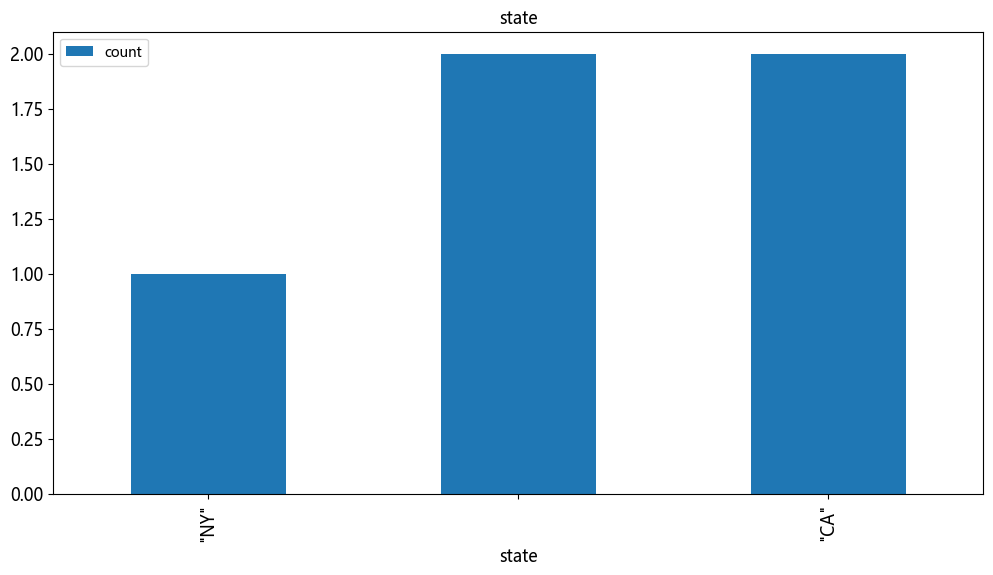

In [34]:
%matplotlib inline
import matplotlib.pyplot as plt

ax = GroupByState_pandas_df['count'].plot(kind='bar', title='state', figsize=(12, 6), legend=True, fontsize=12)
ax.set_xlabel('state', fontsize=12)
plt.show()

## 收尾

两种创建临时视图的写法差异：

| 写法 | 生命周期 | 说明 |
| --- | --- | --- |
| `registerTempTable` | 当前 session | 课件用的老 API，Spark 2.0 起标记废弃，运行会有 FutureWarning |
| `createOrReplaceTempView` | 当前 session | 现行推荐写法，可重复创建并覆盖 |
| `createGlobalTempView` | 跨 session | 用 `global_temp.表名` 访问 |

In [35]:
spark.stop()